# 04 — EBAMTN Components: Multi-scale Attention TCN

Implementation of Model A from Xie et al. (2025), Algorithm 1, for joint PM10/PM2.5 forecasting. The input features, chronological splits, train-only scalers, and split-local windows are copied from notebook 03.

## 1. Configuration

These settings retain notebook 03's lookback, horizons, batch size, epoch limit, learning rate, and seed, with the requested regularization and Model A channel configuration.

In [13]:

from pathlib import Path

LOOKBACK = 48
HORIZONS = [1, 6, 24]
BATCH_SIZE = 256
EPOCHS = 50
LR = 1e-3
HIDDEN = 64
LAYERS = 2
DROPOUT = 0.1
RANDOM_SEED = 42
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0
PATIENCE = 8
FUSED_CHANNELS = 64
FORCE_RETRAIN = False
SCHEDULER_PATIENCE = 3

DATA_PATH = Path(r"C:\Users\jains\Downloads\Air quality dataset\cleaned\air_quality_all_stations_cleaned.csv")
RESULTS_DIR = Path.cwd() / "ebamtn_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Data: {DATA_PATH}")
print(f"Results: {RESULTS_DIR.resolve()}")


Data: C:\Users\jains\Downloads\Air quality dataset\cleaned\air_quality_all_stations_cleaned.csv
Results: E:\coding\DL2project\ebamtn_results


## 2. Imports, seed, and device

Imports and deterministic seed/device setup are copied from notebook 03. The selected device is CUDA when available and CPU otherwise.

In [14]:

import copy
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(8, torch.get_num_threads()))
print(f"PyTorch: {torch.__version__}; device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

from typing import Sequence


PyTorch: 2.15.0+cpu; device: cpu


## 3. Data and chronological splits (copied from notebook 03)

Loads the same cleaned CSV and selected features, verifies the requested split dates, and excludes wind direction while retaining wind speed.

In [15]:

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Cleaned data file not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, parse_dates=["datetime"])
FEATURES = [
    "PM10", "PM2.5", "temperature", "rain", "pressure", "precipitation",
    "wind_speed", "clouds_ordinal", "hour_sin", "hour_cos",
    "day_of_year_sin", "day_of_year_cos",
]
TARGETS = ["PM10", "PM2.5"]
required_columns = ["datetime", "station", *FEATURES]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns missing from cleaned data: {missing_columns}")
# Directional wind fields are intentionally excluded; wind_speed remains a feature.
df = df[required_columns].sort_values(["station", "datetime"]).reset_index(drop=True)
if df.duplicated(["station", "datetime"]).any():
    raise ValueError("Duplicate station/timestamp keys must be resolved before window creation.")

all_timestamps = pd.DatetimeIndex(df["datetime"].drop_duplicates().sort_values())
train_cut_idx = int(len(all_timestamps) * 0.70)
validation_cut_idx = int(len(all_timestamps) * 0.85)
if train_cut_idx <= 0 or validation_cut_idx <= train_cut_idx or validation_cut_idx >= len(all_timestamps):
    raise ValueError("Not enough distinct timestamps to create 70/15/15 chronological splits.")
TRAIN_START, TRAIN_END = all_timestamps[0], all_timestamps[train_cut_idx - 1]
VAL_START, VAL_END = all_timestamps[train_cut_idx], all_timestamps[validation_cut_idx - 1]
TEST_START, TEST_END = all_timestamps[validation_cut_idx], all_timestamps[-1]
print(f"Rows: {len(df):,}; stations: {df['station'].nunique()}; features: {len(FEATURES)}")
print(f"Train:      {TRAIN_START} through {TRAIN_END}")
print(f"Validation: {VAL_START} through {VAL_END}")
print(f"Test:       {TEST_START} through {TEST_END}")
print("Every station uses these same chronological cut dates.")
print(f"Wind-direction input columns retained: {[c for c in df.columns if 'wind_direction' in c]}")
expected_dates = [
    "2024-05-02 20:00:00", "2025-06-18 01:00:00",
    "2025-06-18 02:00:00", "2025-09-14 04:00:00",
    "2025-09-14 05:00:00", "2025-12-11 07:00:00",
]
actual_dates = [str(x) for x in [TRAIN_START, TRAIN_END, VAL_START, VAL_END, TEST_START, TEST_END]]
if actual_dates != expected_dates:
    raise ValueError(f"Split dates differ from requested/LSTM dates: {actual_dates}")


Rows: 296,100; stations: 21; features: 12
Train:      2024-05-02 20:00:00 through 2025-06-18 01:00:00
Validation: 2025-06-18 02:00:00 through 2025-09-14 04:00:00
Test:       2025-09-14 05:00:00 through 2025-12-11 07:00:00
Every station uses these same chronological cut dates.
Wind-direction input columns retained: []


## 4. Train-only scaling and split-local windows (copied from notebook 03)

Uses the same per-station train-fitted StandardScaler, train-median NaN handling, jointly valid PM targets, and 48-step window construction.

In [16]:

class WindowDataset(Dataset):
    '''Lazily slice windows so the full overlapping window tensor stays out of memory.'''
    def __init__(self, station_arrays, records, horizon):
        self.station_arrays = station_arrays
        self.records = records
        self.horizon = horizon

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        station_idx, origin_idx, target_idx = self.records[index]
        arrays = self.station_arrays[station_idx]
        x_start = origin_idx - LOOKBACK + 1
        x = arrays["x"][x_start:origin_idx + 1]
        y_scaled = arrays["y_scaled"][target_idx]
        y_original = arrays["y_original"][target_idx]
        persistence = arrays["persistence"][origin_idx]
        return (
            torch.from_numpy(x), torch.from_numpy(y_scaled),
            torch.tensor(station_idx, dtype=torch.long),
            torch.from_numpy(y_original), torch.from_numpy(persistence),
        )

def build_split_datasets(horizon):
    '''Fit station scalers on train only and create windows contained in each split.'''
    if horizon < 1:
        raise ValueError("HORIZON must be >= 1")
    split_bounds = {
        "train": (TRAIN_START, TRAIN_END),
        "validation": (VAL_START, VAL_END),
        "test": (TEST_START, TEST_END),
    }
    stations = sorted(df["station"].unique())
    station_arrays = {name: [] for name in split_bounds}
    records = {name: [] for name in split_bounds}
    station_scalers = {}
    for station_idx, station in enumerate(stations):
        station_df = df.loc[df["station"].eq(station)].sort_values("datetime").reset_index(drop=True)
        train_mask = station_df["datetime"].between(TRAIN_START, TRAIN_END)
        if train_mask.sum() <= LOOKBACK + horizon:
            raise ValueError(f"Station {station} has too few training rows for the configured window and horizon.")
        train_features = station_df.loc[train_mask, FEATURES].astype(float)
        medians = train_features.median()
        if medians.isna().any():
            bad = medians.index[medians.isna()].tolist()
            raise ValueError(f"Training features entirely missing for station {station}: {bad}")
        feature_scaler = StandardScaler()
        feature_scaler.fit(train_features.fillna(medians).to_numpy(dtype=np.float64))
        target_scalers = {}
        for target in TARGETS:
            valid_train_target = station_df.loc[train_mask, target].dropna().to_numpy(dtype=np.float64).reshape(-1, 1)
            if len(valid_train_target) == 0:
                raise ValueError(f"No valid training targets for {station} / {target}")
            target_scalers[target] = StandardScaler().fit(valid_train_target)
        station_scalers[station] = {
            "features": feature_scaler, "targets": target_scalers, "medians": medians
        }

        # Transform each split independently; no window can cross a split boundary.
        for split_name, (start, end) in split_bounds.items():
            part = station_df.loc[station_df["datetime"].between(start, end)].reset_index(drop=True)
            raw_x = part[FEATURES].astype(float).fillna(medians).to_numpy(dtype=np.float64)
            x_scaled = feature_scaler.transform(raw_x).astype(np.float32)
            y_original = part[TARGETS].to_numpy(dtype=np.float64)
            y_scaled = np.full(y_original.shape, np.nan, dtype=np.float32)
            persistence = part[TARGETS].to_numpy(dtype=np.float64)
            for target_idx, target in enumerate(TARGETS):
                valid = np.isfinite(y_original[:, target_idx])
                target_scaler = target_scalers[target]
                y_scaled[valid, target_idx] = target_scaler.transform(
                    y_original[valid, target_idx].reshape(-1, 1)
                ).ravel().astype(np.float32)
                # The last input observation is the persistence forecast origin.
                input_column_idx = FEATURES.index(target)
            # Preserve the source notebook's persistence arrays at the forecast origin.
            persistence[:, target_idx] = part[target].to_numpy(dtype=np.float64)
            local_arrays = {
                "x": x_scaled, "y_scaled": y_scaled,
                "y_original": y_original.astype(np.float32),
                "persistence": persistence.astype(np.float32),
            }
            station_arrays[split_name].append(local_arrays)
            first_target = LOOKBACK - 1 + horizon
            for target_pos in range(first_target, len(part)):
                origin_pos = target_pos - horizon
                if np.isfinite(y_original[target_pos]).all():
                    records[split_name].append((station_idx, origin_pos, target_pos))

    datasets = {
        name: WindowDataset(station_arrays[name], records[name], horizon)
        for name in split_bounds
    }
    return datasets, station_scalers, stations

print(f"Window builder ready: lookback={LOOKBACK}; horizons={HORIZONS}.")


Window builder ready: lookback=48; horizons=[1, 6, 24].


## 5. DataLoaders and window counts

Creates the notebook 03 train/validation/test DataLoaders. The split sizes are printed for each horizon when it is prepared for training.

In [17]:

def make_dataloaders(
    datasets: dict[str, WindowDataset],
) -> tuple[dict[str, DataLoader], torch.Generator]:
    '''Create the shared train, validation, and test loaders.'''
    counts = {name: len(dataset) for name, dataset in datasets.items()}
    print(
        "Windows train/validation/test = "
        f"{counts['train']:,}/{counts['validation']:,}/{counts['test']:,}"
    )
    train_generator = torch.Generator().manual_seed(RANDOM_SEED)
    loaders = {
        "train": DataLoader(
            datasets["train"], batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
            pin_memory=DEVICE.type == "cuda",
            generator=train_generator,
        ),
        "validation": DataLoader(
            datasets["validation"], batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
            pin_memory=DEVICE.type == "cuda",
        ),
        "test": DataLoader(
            datasets["test"], batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
            pin_memory=DEVICE.type == "cuda",
        ),
    }
    return loaders, train_generator


## 6. Model A: multi-scale attention TCN

The three branches use kernels 3/5/7 and project to 64 channels before attention-weighted fusion. A dilation-16 layer is added after 1/2/4/8 because those four stack layers plus the widest branch yield only a 37-step receptive field, short of the 48-step input.

In [18]:

BRANCH_KERNELS = (3, 5, 7)
BRANCH_CHANNELS = (32, 64, 128)
BASE_DILATIONS = (1, 2, 4, 8)
DILATIONS = (*BASE_DILATIONS, 16)

def receptive_field(kernel_size: int, dilations: Sequence[int], initial_field: int = 1) -> int:
    '''Return the receptive field for sequential stride-one causal convolutions.'''
    return initial_field + (kernel_size - 1) * sum(dilations)

MULTISCALE_RECEPTIVE_FIELD = max(BRANCH_KERNELS)
BASE_RECEPTIVE_FIELD = receptive_field(
    kernel_size=3,
    dilations=BASE_DILATIONS,
    initial_field=MULTISCALE_RECEPTIVE_FIELD,
)
RECEPTIVE_FIELD = receptive_field(
    kernel_size=3,
    dilations=DILATIONS,
    initial_field=MULTISCALE_RECEPTIVE_FIELD,
)
print(
    f"Receptive field with dilations {BASE_DILATIONS}: {BASE_RECEPTIVE_FIELD}; "
    f"with added dilation 16: {RECEPTIVE_FIELD}; LOOKBACK={LOOKBACK}."
)
if RECEPTIVE_FIELD < LOOKBACK:
    raise ValueError(
        f"Model receptive field {RECEPTIVE_FIELD} does not cover LOOKBACK={LOOKBACK}."
    )

class CausalConv1d(nn.Module):
    '''Stride-one Conv1d padded only on the left, preserving sequence length.'''

    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        kernel_size: int,
        dilation: int = 1,
        bias: bool = True,
    ) -> None:
        super().__init__()
        if min(in_channels, out_channels, kernel_size, dilation) < 1:
            raise ValueError("Channels, kernel size, and dilation must be positive.")
        self.left_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            stride=1,
            padding=0,
            dilation=dilation,
            bias=bias,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(F.pad(x, (self.left_padding, 0)))

class MultiScaleAttentionBlock(nn.Module):
    '''Fuse three causal convolution branches with sample-wise attention.'''

    def __init__(
        self,
        in_channels: int,
        fused_channels: int = FUSED_CHANNELS,
        dropout: float = DROPOUT,
    ) -> None:
        super().__init__()
        self.branches = nn.ModuleList([
            nn.Sequential(
                CausalConv1d(in_channels, branch_channels, kernel_size, dilation=1),
                nn.BatchNorm1d(branch_channels),
                nn.ReLU(),
                nn.Dropout(dropout),
            )
            for kernel_size, branch_channels in zip(BRANCH_KERNELS, BRANCH_CHANNELS)
        ])
        # Project unequal branch widths to one common width before weighted summation.
        self.projections = nn.ModuleList([
            nn.Conv1d(branch_channels, fused_channels, kernel_size=1)
            for branch_channels in BRANCH_CHANNELS
        ])
        # Per-branch scoring supports the different descriptor sizes (32, 64, 128).
        self.scorers = nn.ModuleList([
            nn.Linear(branch_channels, 1) for branch_channels in BRANCH_CHANNELS
        ])

    def forward(
        self,
        x: torch.Tensor,
        return_attention: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
        branch_outputs = [
            branch(x) for branch in self.branches
        ]
        scores = torch.cat([
            scorer(branch_output.mean(dim=-1))
            for scorer, branch_output in zip(self.scorers, branch_outputs)
        ], dim=1)
        attention = torch.softmax(scores, dim=1)
        projected = [
            projection(branch_output)
            for projection, branch_output in zip(self.projections, branch_outputs)
        ]
        fused = torch.zeros_like(projected[0])
        for branch_index, branch_output in enumerate(projected):
            weight = attention[:, branch_index].view(-1, 1, 1)
            fused = fused + weight * branch_output
        if return_attention:
            return fused, attention
        return fused

class DilatedSkipStack(nn.Module):
    '''Apply causal dilations and sum a 1x1 projected skip from every layer.'''

    def __init__(
        self,
        channels: int = FUSED_CHANNELS,
        dilations: Sequence[int] = DILATIONS,
        dropout: float = DROPOUT,
    ) -> None:
        super().__init__()
        self.dilations = tuple(dilations)
        self.layers = nn.ModuleList([
            nn.Sequential(
                CausalConv1d(channels, channels, kernel_size=3, dilation=dilation),
                nn.BatchNorm1d(channels),
                nn.ReLU(),
                nn.Dropout(dropout),
            )
            for dilation in self.dilations
        ])
        self.skip_projections = nn.ModuleList([
            nn.Conv1d(channels, channels, kernel_size=1)
            for _ in self.dilations
        ])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        skip_outputs = []
        hidden = x
        for layer, skip_projection in zip(self.layers, self.skip_projections):
            hidden = layer(hidden)
            skip_outputs.append(skip_projection(hidden))
        return torch.stack(skip_outputs, dim=0).sum(dim=0)

class MultiScaleAttentionTCN(nn.Module):
    '''Jointly predict PM10 and PM2.5 from a batch of (batch, time, features).'''

    def __init__(
        self,
        input_size: int,
        fused_channels: int = FUSED_CHANNELS,
        dropout: float = DROPOUT,
    ) -> None:
        super().__init__()
        self.attention_block = MultiScaleAttentionBlock(
            input_size, fused_channels=fused_channels, dropout=dropout
        )
        self.dilated_stack = DilatedSkipStack(
            channels=fused_channels, dilations=DILATIONS, dropout=dropout
        )
        self.head = nn.Sequential(
            nn.Linear(fused_channels, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 2),
        )

    def forward(
        self,
        x: torch.Tensor,
        return_attention: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
        if x.ndim != 3:
            raise ValueError("Expected input shape (batch, time, features).")
        channels_first = x.transpose(1, 2)
        fused, attention = self.attention_block(
            channels_first, return_attention=True
        )
        sequence = self.dilated_stack(fused)
        prediction = self.head(sequence[:, :, -1])
        if return_attention:
            return prediction, attention
        return prediction


Receptive field with dilations (1, 2, 4, 8): 37; with added dilation 16: 69; LOOKBACK=48.


## 7. Model sanity check

Check the Model A output shape, attention-weight normalization, and trainable parameter count using a synthetic input only.

In [19]:

model_a = MultiScaleAttentionTCN(input_size=len(FEATURES)).to(DEVICE)
model_a.eval()
sanity_input = torch.randn(8, LOOKBACK, len(FEATURES), device=DEVICE)
with torch.no_grad():
    sanity_output, sanity_attention = model_a(sanity_input, return_attention=True)
assert sanity_output.shape == (8, 2), f"Unexpected output shape: {sanity_output.shape}"
assert sanity_attention.shape == (8, 3), f"Unexpected attention shape: {sanity_attention.shape}"
assert torch.allclose(
    sanity_attention.sum(dim=1),
    torch.ones(8, device=DEVICE),
    atol=1e-6,
)
parameter_count = sum(parameter.numel() for parameter in model_a.parameters() if parameter.requires_grad)
print(f"Output shape: {tuple(sanity_output.shape)}; attention shape: {tuple(sanity_attention.shape)}")
print(f"Model A trainable parameters: {parameter_count:,}")


Output shape: (8, 2); attention shape: (8, 3)
Model A trainable parameters: 118,661


## 8. Causality check

Change only the last input time step and verify that earlier outputs of the causal convolution stack stay unchanged. Batch normalization is put in evaluation mode so its fixed running statistics do not mix time positions.

In [20]:

causality_stack = DilatedSkipStack().to(DEVICE).eval()
causal_input = torch.randn(2, FUSED_CHANNELS, LOOKBACK, device=DEVICE)
changed_input = causal_input.clone()
changed_input[:, :, -1] += 1.0
with torch.no_grad():
    original_sequence = causality_stack(causal_input)
    changed_sequence = causality_stack(changed_input)
assert torch.allclose(
    original_sequence[..., :-1],
    changed_sequence[..., :-1],
    rtol=0.0,
    atol=0.0,
), "A later input changed an earlier causal-stack output."
print("Causality check passed: changing the final time step leaves all earlier stack outputs unchanged.")


Causality check passed: changing the final time step leaves all earlier stack outputs unchanged.


## 9. Parameter-count reference

Always report Model A. If notebook 03's pooled LSTM, TCN, or 1D-CNN classes are already present in this kernel, include their counts as well.

In [21]:

def count_parameters(model: nn.Module) -> int:
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

parameter_rows = [{
    "model": "Model A — Multi-scale attention TCN",
    "trainable_parameters": count_parameters(MultiScaleAttentionTCN(len(FEATURES))),
}]
reference_classes = {
    "LSTM (03)": "PooledLSTM",
    "TCN (03)": "PooledTCN",
    "1D-CNN (03)": "PooledCNN1D",
}
for label, class_name in reference_classes.items():
    model_class = globals().get(class_name)
    if isinstance(model_class, type) and issubclass(model_class, nn.Module):
        reference_model = model_class(len(FEATURES))
        parameter_rows.append({
            "model": label,
            "trainable_parameters": count_parameters(reference_model),
        })
display(pd.DataFrame(parameter_rows))


,model,trainable_parameters
0,Model A — Multi-scale attention TCN,118661


## 10. Reusable training and evaluation functions

These functions accept a model so later architectures can share the same Adam/MSE, scheduler, clipping, early stopping, and original-scale pooled/per-station test evaluation.

In [22]:

def regression_metrics(actual, predicted):
    '''Compute finite-value MAE, RMSE, R2, and sample count.'''
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual, predicted = actual[valid], predicted[valid]
    if not len(actual):
        return {"MAE": np.nan, "RMSE": np.nan, "R2": np.nan, "n": 0}
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted) if len(actual) >= 2 else np.nan,
        "n": len(actual),
    }

def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
) -> float:
    '''Run one training epoch and clip the global gradient norm.'''
    model.train()
    loss_sum, sample_count = 0.0, 0
    for x, y, _, _, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(x), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        optimizer.step()
        loss_sum += loss.item() * len(x)
        sample_count += len(x)
    if sample_count == 0:
        raise ValueError("Training DataLoader produced no samples.")
    return loss_sum / sample_count

def validate_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
) -> float:
    '''Compute sample-weighted validation MSE without updating model state.'''
    model.eval()
    loss_sum, sample_count = 0.0, 0
    with torch.no_grad():
        for x, y, _, _, _ in loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            loss_sum += criterion(model(x), y).item() * len(x)
            sample_count += len(x)
    if sample_count == 0:
        raise ValueError("Validation DataLoader produced no samples.")
    return loss_sum / sample_count

def fit_model(
    model: nn.Module,
    train_loader: DataLoader,
    validation_loader: DataLoader,
    train_generator: torch.Generator,
    resume_path: Path,
) -> dict[str, object]:
    '''Train or resume a model, saving its complete state after each epoch.'''
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
    )
    criterion = nn.MSELoss()
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=SCHEDULER_PATIENCE
    )
    history = {"train_loss": [], "validation_loss": []}
    best_state = None
    best_validation_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    start_epoch = 1
    elapsed_before_resume = 0.0

    if resume_path.is_file():
        checkpoint = torch.load(resume_path, map_location="cpu", weights_only=True)
        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scheduler.load_state_dict(checkpoint["scheduler_state"])
        train_generator.set_state(checkpoint["train_generator_state"])
        torch.set_rng_state(checkpoint["torch_rng_state"])
        cuda_rng_states = checkpoint["cuda_rng_states"]
        if torch.cuda.is_available() and cuda_rng_states:
            torch.cuda.set_rng_state_all(cuda_rng_states)
        history = checkpoint["history"]
        best_state = checkpoint["best_state"]
        best_validation_loss = checkpoint["best_validation_loss"]
        best_epoch = checkpoint["best_epoch"]
        epochs_without_improvement = checkpoint["epochs_without_improvement"]
        start_epoch = checkpoint["epoch"] + 1
        elapsed_before_resume = checkpoint["elapsed_seconds"]
        print(f"Resuming from completed epoch {start_epoch - 1} ({resume_path}).")

    started = time.perf_counter()
    for epoch in range(start_epoch, EPOCHS + 1):
        if epochs_without_improvement >= PATIENCE:
            print("Early-stopping patience was already exhausted in the saved checkpoint.")
            break
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        validation_loss = validate_one_epoch(model, validation_loader, criterion)
        scheduler.step(validation_loss)
        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_loss)
        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        print(
            f"epoch {epoch:02d}/{EPOCHS} | train={train_loss:.5f} | "
            f"val={validation_loss:.5f} | "
            f"lr={optimizer.param_groups[0]['lr']:.2e}"
        )

        checkpoint = {
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "best_state": best_state,
            "best_validation_loss": best_validation_loss,
            "best_epoch": best_epoch,
            "epochs_without_improvement": epochs_without_improvement,
            "history": history,
            "elapsed_seconds": elapsed_before_resume + time.perf_counter() - started,
            "train_generator_state": train_generator.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_states": torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else [],
        }
        temporary_path = resume_path.with_suffix(resume_path.suffix + ".tmp")
        torch.save(checkpoint, temporary_path)
        temporary_path.replace(resume_path)

        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping after {PATIENCE} epochs without improvement.")
            break

    if best_state is None:
        raise RuntimeError("Training ended without a finite validation checkpoint.")
    model.load_state_dict(best_state)
    return {
        "history": history,
        "best_state": best_state,
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "epochs_run": len(history["train_loss"]),
        "training_seconds": elapsed_before_resume + time.perf_counter() - started,
    }

def evaluate_model(
    model: nn.Module,
    horizon: int,
    test_loader: DataLoader,
    station_scalers: dict,
    stations: list[str],
) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''Return original-scale pooled/per-station metrics and test predictions.'''
    model.eval()
    prediction_scaled, actual_original = [], []
    persistence_original, station_indices = [], []
    with torch.no_grad():
        for x, _, station_id, actual, persistence in test_loader:
            prediction_scaled.append(model(x.to(DEVICE, non_blocking=True)).cpu().numpy())
            actual_original.append(actual.numpy())
            persistence_original.append(persistence.numpy())
            station_indices.append(station_id.numpy())
    prediction_scaled = np.concatenate(prediction_scaled)
    actual_original = np.concatenate(actual_original)
    persistence_original = np.concatenate(persistence_original)
    station_indices = np.concatenate(station_indices)
    station_names = np.asarray(stations, dtype=object)[station_indices]

    prediction_original = np.empty_like(prediction_scaled, dtype=np.float64)
    for station_idx, station in enumerate(stations):
        rows = station_indices == station_idx
        for target_idx, target in enumerate(TARGETS):
            scaler = station_scalers[station]["targets"][target]
            prediction_original[rows, target_idx] = scaler.inverse_transform(
                prediction_scaled[rows, target_idx].reshape(-1, 1)
            ).ravel()

    test_dates = []
    # Match notebook 03's station-major, chronological prediction ordering.
    for station in stations:
        part = df.loc[
            df["station"].eq(station)
            & df["datetime"].between(TEST_START, TEST_END)
        ].reset_index(drop=True)
        first_target = LOOKBACK - 1 + horizon
        valid_positions = [
            pos for pos in range(first_target, len(part))
            if np.isfinite(part.loc[pos, TARGETS].to_numpy(dtype=float)).all()
        ]
        test_dates.extend(part.loc[valid_positions, "datetime"].tolist())
    predictions = pd.DataFrame({
        "station": station_names,
        "datetime": test_dates,
        "PM10_actual": actual_original[:, 0],
        "PM10_predicted": prediction_original[:, 0],
        "PM2.5_actual": actual_original[:, 1],
        "PM2.5_predicted": prediction_original[:, 1],
        "PM10_persistence": persistence_original[:, 0],
        "PM2.5_persistence": persistence_original[:, 1],
    })

    metric_rows = []
    for target_idx, target in enumerate(TARGETS):
        groups = [("overall", np.ones(len(station_names), dtype=bool))] + [
            (station, station_names == station) for station in stations
        ]
        for group, mask in groups:
            values = regression_metrics(
                actual_original[mask, target_idx],
                prediction_original[mask, target_idx],
            )
            metric_rows.append({
                "horizon": horizon,
                "target": target,
                "station": group,
                "method": "Model A",
                **values,
            })
    return pd.DataFrame(metric_rows), predictions


## 11. Train and evaluate Model A by horizon

Set `HORIZONS = [6]` in the configuration for a quick single-horizon run. A full resume checkpoint is atomically saved after every completed epoch; an interrupted epoch repeats, while completed epochs are restored with optimizer, scheduler, history, shuffle-generator, and RNG state. After a kernel restart, rerun the setup/model/training-function cells, then this cell. A completed best-weights file skips that horizon unless `FORCE_RETRAIN = True`; when forced, any in-progress resume checkpoint is still used.

Windows train/validation/test = 203,749/42,142/43,041
epoch 01/50 | train=0.15479 | val=0.06205 | lr=1.00e-03
epoch 02/50 | train=0.12531 | val=0.06150 | lr=1.00e-03
epoch 03/50 | train=0.12110 | val=0.06207 | lr=1.00e-03
epoch 04/50 | train=0.12085 | val=0.05902 | lr=1.00e-03
epoch 05/50 | train=0.11849 | val=0.05848 | lr=1.00e-03
epoch 06/50 | train=0.11749 | val=0.05835 | lr=1.00e-03
epoch 07/50 | train=0.11769 | val=0.05881 | lr=1.00e-03
epoch 08/50 | train=0.11550 | val=0.06211 | lr=1.00e-03
epoch 09/50 | train=0.11588 | val=0.05741 | lr=1.00e-03
epoch 10/50 | train=0.11530 | val=0.05802 | lr=1.00e-03
epoch 11/50 | train=0.11453 | val=0.05632 | lr=1.00e-03
epoch 12/50 | train=0.11459 | val=0.05696 | lr=1.00e-03
epoch 13/50 | train=0.11386 | val=0.05713 | lr=1.00e-03
epoch 14/50 | train=0.11312 | val=0.05700 | lr=1.00e-03
epoch 15/50 | train=0.11281 | val=0.05708 | lr=5.00e-04
epoch 16/50 | train=0.10898 | val=0.05625 | lr=5.00e-04
epoch 17/50 | train=0.10884 | val=0.05618 | lr=5.0

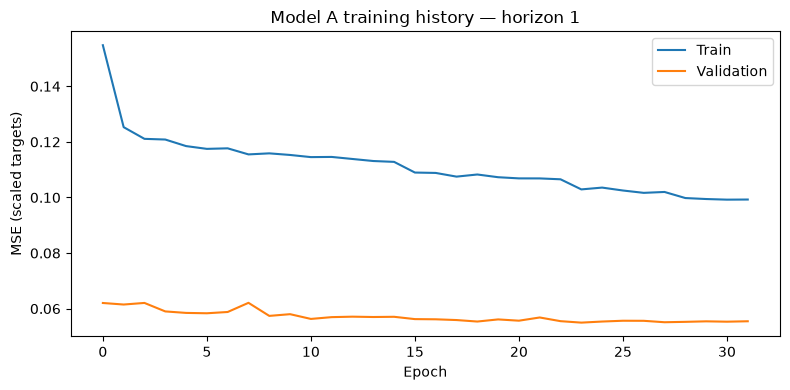

H=1: best epoch 24; training time 59797.5s


,horizon,target,station,method,MAE,RMSE,R2,n
0,1,PM10,overall,Model A,2.731283,4.832126,0.840511,43041
1,1,PM10,E403,Model A,2.669568,4.627589,0.858664,2067
2,1,PM10,E404,Model A,2.660690,4.641836,0.865200,2067
3,1,PM10,E405,Model A,2.352443,3.630941,0.901906,2067
4,1,PM10,E407,Model A,2.373078,4.314770,0.749869,2061
5,1,PM10,E408,Model A,1.893356,2.783541,0.875813,2067


Windows train/validation/test = 203,644/42,037/42,936
epoch 01/50 | train=0.33406 | val=0.09685 | lr=1.00e-03
epoch 02/50 | train=0.28922 | val=0.09140 | lr=1.00e-03
epoch 03/50 | train=0.27120 | val=0.09168 | lr=1.00e-03
epoch 04/50 | train=0.25967 | val=0.09284 | lr=1.00e-03
epoch 05/50 | train=0.25094 | val=0.09702 | lr=1.00e-03
epoch 06/50 | train=0.24287 | val=0.09433 | lr=5.00e-04
epoch 07/50 | train=0.22111 | val=0.09266 | lr=5.00e-04
epoch 08/50 | train=0.21470 | val=0.09724 | lr=5.00e-04
epoch 09/50 | train=0.20939 | val=0.09674 | lr=5.00e-04
epoch 10/50 | train=0.20574 | val=0.09497 | lr=2.50e-04
Early stopping after 8 epochs without improvement.


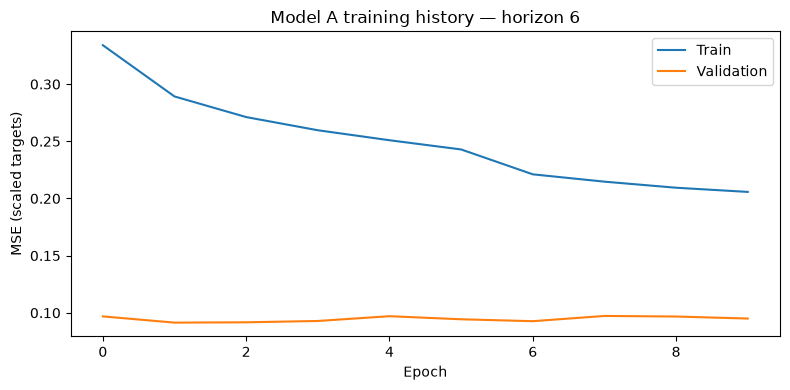

H=6: best epoch 2; training time 3094.3s


,horizon,target,station,method,MAE,RMSE,R2,n
0,6,PM10,overall,Model A,5.570065,8.155341,0.546395,42936
1,6,PM10,E403,Model A,5.488281,7.729001,0.606403,2062
2,6,PM10,E404,Model A,5.628783,7.912233,0.609152,2062
3,6,PM10,E405,Model A,5.124243,6.803566,0.656232,2062
4,6,PM10,E407,Model A,5.094580,7.308036,0.283926,2056
5,6,PM10,E408,Model A,4.302492,5.772676,0.467036,2062


Windows train/validation/test = 203,266/41,659/42,558
epoch 01/50 | train=0.44121 | val=0.13643 | lr=1.00e-03
epoch 02/50 | train=0.36263 | val=0.13970 | lr=1.00e-03
epoch 03/50 | train=0.32560 | val=0.14459 | lr=1.00e-03
epoch 04/50 | train=0.30256 | val=0.13407 | lr=1.00e-03
epoch 05/50 | train=0.28457 | val=0.13602 | lr=1.00e-03
epoch 06/50 | train=0.27451 | val=0.15036 | lr=1.00e-03
epoch 07/50 | train=0.26223 | val=0.15009 | lr=1.00e-03
epoch 08/50 | train=0.25430 | val=0.14093 | lr=5.00e-04
epoch 09/50 | train=0.22935 | val=0.14279 | lr=5.00e-04
epoch 10/50 | train=0.22059 | val=0.13445 | lr=5.00e-04
epoch 11/50 | train=0.21605 | val=0.13608 | lr=5.00e-04
epoch 12/50 | train=0.21229 | val=0.13764 | lr=2.50e-04
Early stopping after 8 epochs without improvement.


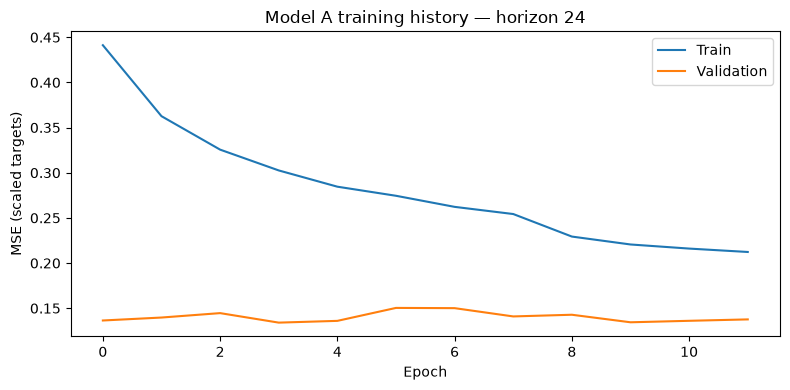

H=24: best epoch 4; training time 40312.7s


,horizon,target,station,method,MAE,RMSE,R2,n
0,24,PM10,overall,Model A,7.584839,10.291804,0.279867,42558
1,24,PM10,E403,Model A,7.575785,10.126826,0.311757,2044
2,24,PM10,E404,Model A,8.069999,10.915997,0.257856,2044
3,24,PM10,E405,Model A,7.134249,9.388426,0.345632,2044
4,24,PM10,E407,Model A,6.404245,8.519475,0.029723,2038
5,24,PM10,E408,Model A,6.003549,7.681837,0.060287,2044


,model,horizon,best_epoch,epochs_run,best_validation_loss,training_time_seconds,trainable_parameters
0,Model A — Multi-scale attention TCN,1,24,32,0.054985,59797.466140,118661
1,Model A — Multi-scale attention TCN,6,2,10,0.091401,3094.341643,118661
2,Model A — Multi-scale attention TCN,24,4,12,0.134069,40312.670978,118661


In [23]:

def run_model_a_horizon(horizon: int) -> dict[str, object] | None:
    '''Train/evaluate one horizon, or skip it when its completed weights exist.'''
    weights_path = RESULTS_DIR / f"model_a_horizon_{horizon}_best.pt"
    resume_path = RESULTS_DIR / f"model_a_horizon_{horizon}_resume.pt"
    metrics_path = RESULTS_DIR / f"model_a_horizon_{horizon}_metrics.csv"
    training_path = RESULTS_DIR / f"model_a_horizon_{horizon}_training.csv"
    predictions_path = RESULTS_DIR / f"model_a_horizon_{horizon}_test_predictions.csv"
    loss_path = RESULTS_DIR / f"model_a_horizon_{horizon}_loss.png"

    if weights_path.is_file() and not FORCE_RETRAIN:
        print(
            f"Skipping H={horizon}: best weights already exist at {weights_path}. "
            "Set FORCE_RETRAIN=True to train this horizon again."
        )
        if training_path.is_file():
            return pd.read_csv(training_path).iloc[0].to_dict()
        return None

    set_seed(RANDOM_SEED)
    datasets, station_scalers, stations = build_split_datasets(horizon)
    loaders, train_generator = make_dataloaders(datasets)
    model = MultiScaleAttentionTCN(input_size=len(FEATURES)).to(DEVICE)
    fit_result = fit_model(
        model=model,
        train_loader=loaders["train"],
        validation_loader=loaders["validation"],
        train_generator=train_generator,
        resume_path=resume_path,
    )
    training_seconds = fit_result["training_seconds"]

    metrics, predictions = evaluate_model(
        model=model,
        horizon=horizon,
        test_loader=loaders["test"],
        station_scalers=station_scalers,
        stations=stations,
    )
    metrics.to_csv(metrics_path, index=False)
    predictions.to_csv(predictions_path, index=False)

    history = fit_result["history"]
    figure, axis = plt.subplots(figsize=(8, 4))
    axis.plot(history["train_loss"], label="Train")
    axis.plot(history["validation_loss"], label="Validation")
    axis.set(
        title=f"Model A training history — horizon {horizon}",
        xlabel="Epoch",
        ylabel="MSE (scaled targets)",
    )
    axis.legend()
    figure.tight_layout()
    figure.savefig(loss_path, dpi=150)
    plt.show()
    plt.close(figure)

    summary = {
        "model": "Model A — Multi-scale attention TCN",
        "horizon": horizon,
        "best_epoch": fit_result["best_epoch"],
        "epochs_run": fit_result["epochs_run"],
        "best_validation_loss": fit_result["best_validation_loss"],
        "training_time_seconds": training_seconds,
        "trainable_parameters": sum(
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        ),
    }
    pd.DataFrame([summary]).to_csv(training_path, index=False)
    # Write best weights atomically and last; their presence marks completion.
    temporary_weights_path = weights_path.with_suffix(weights_path.suffix + ".tmp")
    torch.save(fit_result["best_state"], temporary_weights_path)
    temporary_weights_path.replace(weights_path)
    if resume_path.is_file():
        resume_path.unlink()
    print(
        f"H={horizon}: best epoch {summary['best_epoch']}; "
        f"training time {training_seconds:.1f}s"
    )
    display(metrics.head(6))
    return summary

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
run_summaries = []
for horizon in HORIZONS:
    summary = run_model_a_horizon(horizon)
    if summary is not None:
        run_summaries.append(summary)
if run_summaries:
    summary_frame = pd.DataFrame(run_summaries).drop_duplicates(
        subset=["horizon"], keep="last"
    ).sort_values("horizon")
    summary_frame.to_csv(RESULTS_DIR / "model_a_training_summary.csv", index=False)
    display(summary_frame)
